In [ ]:
# testing saving graphs to file
from RNG_DAG import DAG
import pickle

dags = [DAG(10) for _ in range(5)]
with open("multiple_dags.pkl", "wb") as f:
    pickle.dump(dags, f)

# Load them back
with open("multiple_dags.pkl", "rb") as f:
    loaded_dags = pickle.load(f)

In [14]:
# set up the graphs that will be tested on and save them for later:

from RNG_DAG import DAG
import pickle

graph_sizes = [4, 5, 6, 7, 8, 9, 10, 11]

for size in graph_sizes:
    dag_list = []
    dag_list1 = []
    for i in range(1000):
        dag = DAG(size)
        dag_list1.append((dag, dag.bh_links))
    dag_list1_sorted = sorted(dag_list1, key=lambda x: x[1], reverse=True)[:20]
    dag_list1_sorted = [x[0] for x in dag_list1_sorted]
    dag_list.append(dag_list1_sorted)
    size_str = str(size)
    with open("generated_graphs/bh_dags_" + size_str + ".pkl", "wb") as f:
        pickle.dump(dag_list, f)

In [15]:
# loop through the bh_links graphs and get a count of average number of bh_links per size
bh_links = []
for size in graph_sizes:
    with open("generated_graphs/bh_dags_" + str(size) + ".pkl", "rb") as f:
        dags = pickle.load(f)
    bh_links.append(sum([dag.bh_links for dag in dags[0]]) / 20)

print(bh_links)

# find the highest and lowest per size
bh_links = []
for size in graph_sizes:
    with open("generated_graphs/bh_dags_" + str(size) + ".pkl", "rb") as f:
        dags = pickle.load(f)
    bh_links.append([dag.bh_links for dag in dags[0]])
    print("Size: ", size, " Max: ", max(bh_links[-1]), " Min: ", min(bh_links[-1]))


[2.6, 2.95, 3.25, 2.8, 3.35, 3.05, 3.35, 2.95]
Size:  4  Max:  3  Min:  2
Size:  5  Max:  4  Min:  2
Size:  6  Max:  4  Min:  3
Size:  7  Max:  4  Min:  2
Size:  8  Max:  5  Min:  3
Size:  9  Max:  4  Min:  2
Size:  10  Max:  6  Min:  2
Size:  11  Max:  4  Min:  2


In [18]:
# create the training files
dag_list = []
dag_list1 = []
for i in range(1000):
    dag = DAG(9)
    dag_list1.append((dag, dag.bh_links))
dag_list1_sorted = sorted(dag_list1, key=lambda x: x[1], reverse=True)[:20]
dag_list1_sorted = [x[0] for x in dag_list1_sorted]
dag_list.append(dag_list1_sorted)
size_str = str(size)
with open("generated_graphs/training_bh_dags_" + "9" + ".pkl", "wb") as f:
    pickle.dump(dag_list, f)

{'3-chains': 24, 'diamonds': 7, 'bh-links': 0}


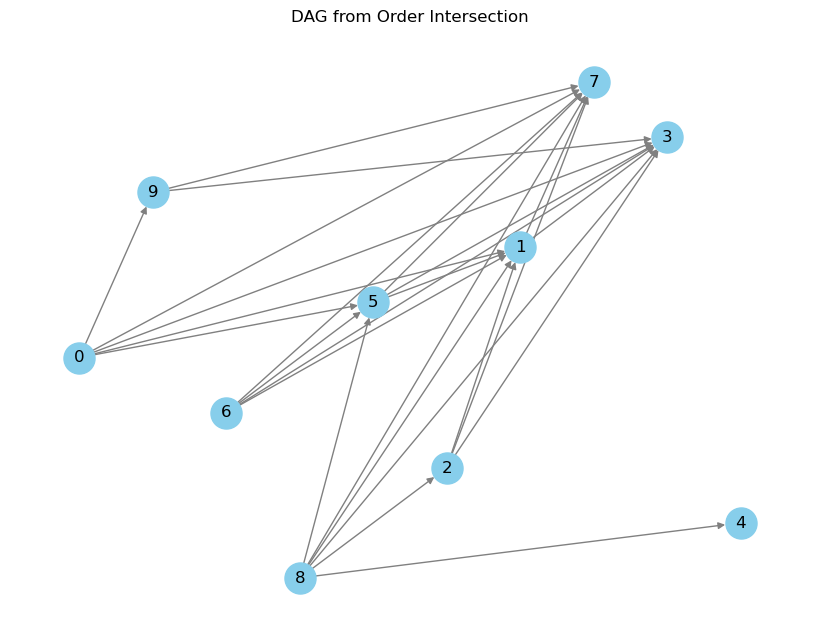

In [14]:
size_10_graphs = []
with open("generated_graphs/dags_10.pkl", "rb") as f:
    size_10_graphs = pickle.load(f)

n = 15

print(size_10_graphs[n].get_counts())
size_10_graphs[n].plot_dag()

In [6]:
# set up naive 3-chain
from RNG_DAG import DAG
from VQALib import CubicProgram, IsingHamiltonian
from QUBO_FUNCTIONS import QUBO_Problem
import numpy as np
import pickle

def get_average_overlaps_from_dag_set(size, function, qubit_num):
    # retrieve the graphs set:
    graphs = []
    with open("generated_graphs/dags_" + str(size) + ".pkl", "rb") as f:
        graphs = pickle.load(f)

    overlaps = []

    for dag in graphs:
        # create a QUBO problem
        three_chain_naive_problem = QUBO_Problem(dag.get_adjacency_matrix(), dag.N, function)
        three_chain_naive_program = CubicProgram(three_chain_naive_problem.linear, three_chain_naive_problem.quadratic, [], qubit_num)
        three_chain_naive_ising = IsingHamiltonian(three_chain_naive_program)
        
        # solve the problem
        correct_bitstring, _ = three_chain_naive_ising.run_numpy_eigensolver()
        correct_bitstring_str = "".join([str(int(x)) for x in correct_bitstring[::-1]])
        print("Correct bitstring: " + str(correct_bitstring))
        
        overlaps_for_this_dag = []
        for i in range(10):
            found_bitstring, probability, overlap = three_chain_naive_ising.run_QAOA([correct_bitstring_str], 4)
            # print("Found bitstring: " + str(found_bitstring))
            # print("Overlap: " + str(overlap))
            # print("--------------------")
            overlaps_for_this_dag.append(overlap)
        
        avg_overlaps_for_this_dag = np.average(overlaps_for_this_dag)
        overlaps.append(avg_overlaps_for_this_dag)
    
    return np.average(overlaps)

graph_sizes = [4, 6, 8, 9, 10, 12, 14, 16, 18]

for size in graph_sizes[:4]:
    average_overlaps = get_average_overlaps_from_dag_set(size, "three-chain", 2*size)
    average_overlap_for_this_size = np.average(average_overlaps)
    print("Average overlap for size " + str(size) + ": " + str(average_overlap_for_this_size))
    
    # save the average overlaps and overlap for this size to a txt file:
    with open("experiment_results/three_chain_quadratic.txt", "a") as f:
        f.write(f"Size: {str(size)}, Average Overlaps: {average_overlaps}, Average Overlap: {average_overlap_for_this_size} \n")
        f.write(f"-------------------------------------------------- \n")

Correct bitstring: [0. 0. 1. 0. 1. 1. 0. 1.]
Correct bitstring: [1. 1. 1. 0. 0. 1. 1. 1.]
Correct bitstring: [0. 0. 1. 1. 1. 1. 1. 0.]
Correct bitstring: [0. 1. 1. 0. 0. 0. 1. 1.]
Correct bitstring: [0. 1. 1. 1. 1. 0. 0. 0.]
Correct bitstring: [0. 1. 1. 0. 1. 1. 0. 1.]
Correct bitstring: [0. 1. 1. 1. 1. 0. 0. 1.]
Correct bitstring: [0. 1. 0. 0. 1. 0. 1. 1.]
Correct bitstring: [1. 0. 1. 1. 0. 1. 0. 0.]
Correct bitstring: [0. 1. 1. 0. 1. 0. 1. 1.]
Correct bitstring: [1. 1. 0. 1. 0. 0. 1. 0.]
Correct bitstring: [1. 1. 0. 0. 0. 1. 1. 0.]
Correct bitstring: [0. 1. 1. 0. 0. 0. 1. 1.]
Correct bitstring: [0. 1. 0. 0. 1. 0. 0. 1.]
Correct bitstring: [1. 1. 0. 1. 1. 0. 1. 0.]
Correct bitstring: [1. 1. 0. 1. 0. 1. 1. 1.]
Correct bitstring: [1. 1. 1. 0. 1. 0. 0. 1.]
Correct bitstring: [1. 0. 1. 0. 0. 1. 0. 0.]
Correct bitstring: [1. 1. 1. 0. 1. 1. 0. 1.]
Correct bitstring: [1. 0. 0. 1. 0. 1. 0. 1.]
Average overlap for size 4: 0.155388671875
Correct bitstring: [1. 0. 1. 1. 1. 0. 0. 1. 1. 1. 0. 1.]


In [3]:
# QAOA complexity scaling function:
from VQALib import CubicProgram, IsingHamiltonian
from qiskit_aer import AerSimulator
from qiskit.circuit.library import QAOAAnsatz
import numpy as np
from RNG_DAG import DAG
from QUBO_FUNCTIONS import QUBO_Problem
import pickle

def run_aer_simulator(graph, function, aer_simulator, optimised_parameters, depth, qubit_mult):
    problem = QUBO_Problem(graph.get_adjacency_matrix(), graph.N, function)
    program = CubicProgram(problem.linear, problem.quadratic, [], qubit_mult*graph.N)
    hamiltonian = IsingHamiltonian(program)
    
    correct_bitstring, _ = hamiltonian.run_numpy_eigensolver()
    correct_bitstrings = ["".join([str(int(x)) for x in correct_bitstring[::-1]])]
    
    qaoa_ansatz = QAOAAnsatz(hamiltonian.qubit_op, reps=depth)
    qaoa_ansatz.measure_active()
    
    parameter_bindings = dict(zip(qaoa_ansatz.parameters, optimised_parameters))
    qaoa_with_parameters = qaoa_ansatz.assign_parameters(parameter_bindings)
    qaoa_with_parameters_decomposed = qaoa_with_parameters.decompose(reps=3)
    
    number_of_shots = 10*pow(2, hamiltonian.qubit_op.num_qubits)
    counts = aer_simulator.run(qaoa_with_parameters_decomposed, shots=number_of_shots).result().get_counts()
    
    probabilities = {bitstring: (count/number_of_shots) \
                                for bitstring, count in counts.items()}
    correct_prob = 0
    for correct_bitstring in correct_bitstrings:
        if correct_bitstring in probabilities.keys():
            correct_prob += probabilities[correct_bitstring]
    if correct_prob == 0:
        correct_prob = 1/(2*pow(2, hamiltonian.qubit_op.num_qubits))
        
    return counts, correct_prob

def QAOA_scaling(function, iterations, qubit_mult, depth):
    
    graph_sizes = [4, 6, 8, 9, 10, 12, 14, 16, 18]
    overlaps_dict = {}
    for size in graph_sizes:
        overlaps_dict[str(size)] = []
    
    for i in range(iterations):
        print(f"Starting iteration {i+1}/{iterations}")
        # denote the beginning of a new iteration in the txt file:
        with open("experiment_results/" + function + "_scaling.txt", "a") as f:
            f.write(f"-------------------------------------------------- \n")
            f.write(f"Iteration: {i} \n")
            f.write(f"-------------------------------------------------- \n")
        
        # generate a graph that the QAOA parameters will be trained on
        training_graph = DAG(9)
        
        # create a QUBO problem out of the training graph
        training_problem = QUBO_Problem(training_graph.get_adjacency_matrix(), training_graph.N, function)
        training_program = CubicProgram(training_problem.linear, training_problem.quadratic, [], qubit_mult*training_graph.N)
        training_ising = IsingHamiltonian(training_program)
        
        # solve the problem
        correct_bitstring, _ = training_ising.run_numpy_eigensolver()
        correct_bitstring_str = "".join([str(int(x)) for x in correct_bitstring[::-1]])
        training_ising.run_QAOA([correct_bitstring_str], depth)
        
        # memorise optimal parameters
        optimised_parameters = training_ising.optimised_parameters
        
        # create the simulator:
        aer_simulator = AerSimulator(method="statevector")
        
        # use the optmised parameters to find the average overlap for each set of graphs:
        average_overlaps = []
        
        for size in graph_sizes[:6]:
            print(f"Processing graph size {size}")
            # retrieve the graph set
            graphs = []
            with open("generated_graphs/dags_" + str(size) + ".pkl", "rb") as f:
                graphs = pickle.load(f)
            
            overlaps = []
            for graph in graphs:
                counts, overlap = run_aer_simulator(graph, function, aer_simulator, optimised_parameters, depth, qubit_mult)
                
                overlaps.append(overlap)
                
            average_overlap = np.average(overlaps)
            
            average_overlaps.append(average_overlap)
            overlaps_dict[str(size)].append(average_overlap)
            
            # save the average overlaps to a txt file:
            with open("experiment_results/" + function + "_scaling.txt", "a") as f:
                f.write(f"Size: {str(size)}, Average Overlap: {average_overlap} \n")
        
        # save the average overlaps for this iteration to a txt file:
        with open("experiment_results/" + function + "_scaling.txt", "a") as f:
            f.write(f"Iteration: {i}, Average Overlaps: {average_overlaps} \n")
            f.write(f"-------------------------------------------------- \n\n")
    
    # save the average overlaps for each size to a txt file:
    with open("experiment_results/" + function + "_scaling.txt", "a") as f:
        f.write(f"Final overlaps dictionary: {overlaps_dict} \n")
        f.write(f"-------------------------------------------------- \n\n")
    return overlaps_dict

overlaps_dict = QAOA_scaling("three-chain", iterations=4, qubit_mult=2, depth=4)

Starting iteration 1/4
Processing graph size 4
Processing graph size 6
Processing graph size 8
Processing graph size 9
Processing graph size 10
Processing graph size 12


Simulation failed and returned the following error message:
ERROR:  [Experiment 0] bad allocation


QiskitError: 'ERROR:  [Experiment 0] bad allocation ,  ERROR: bad allocation'

In [2]:
# show how the number of terms scales with problem size

# for each graph size, find the average number of terms in the QUBO problem
from RNG_DAG import DAG
from QUBO_FUNCTIONS import QUBO_Problem
import pickle
import numpy as np

def get_average_number_of_terms(function):
    
    graph_sizes = [4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 16, 18]
    # retrieve the graphs set:
    number_of_terms_for_sizes = []
    for size in graph_sizes:
        number_of_terms = []
        graphs = []
        with open("generated_graphs/dags_" + str(size) + ".pkl", "rb") as f:
            graphs = pickle.load(f)
        
        for graph in graphs:
            problem = QUBO_Problem(graph.get_adjacency_matrix(), graph.N, function)
            number_of_terms.append(len(problem.quadratic))
        
        number_of_terms_for_sizes.append(np.average(number_of_terms))
    
    return number_of_terms_for_sizes

three_chain_terms = get_average_number_of_terms("three-chain")

three_chain_terms_naive = get_average_number_of_terms("three-chain-naive")
print(three_chain_terms)
print(three_chain_terms_naive)

[4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 14.0, 16.0, 18.0]
[0.85, 0.85, 2.15, 2.6, 5.4, 8.05, 10.1, 13.15, 17.95, 26.65, 33.0, 41.85]


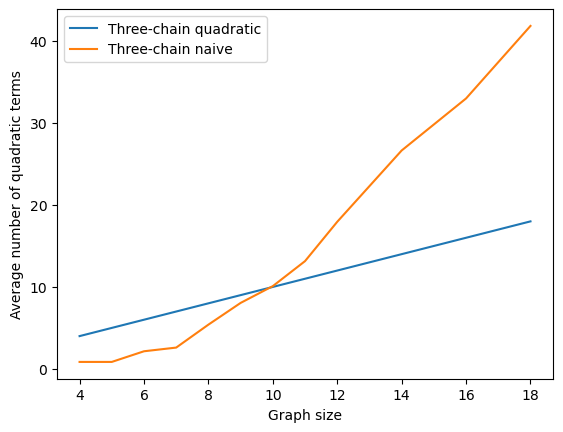

In [3]:
# show how the number of terms scales with problem size on a plot
import matplotlib.pyplot as plt

graph_sizes = [4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 16, 18]

plt.plot(graph_sizes, three_chain_terms, label="Three-chain quadratic")
plt.plot(graph_sizes, three_chain_terms_naive, label="Three-chain naive")
plt.xlabel("Graph size")
plt.ylabel("Average number of quadratic terms")
plt.legend()
plt.show()